# Example of the aitlas toolbox in the context of object detection 

This notebook shows a sample implementation of object detection using the aitlas toolbox. The VEDAI dataset provides images in 2 sizes: 1024x1024 and 512x512. This notebook showcases an example with the 1024x1024 RGB images. Vehicle instances are annotated with oriented bounding boxes. For ease of use, this example translates them into axis-aligned bounding boxes.

## Import the required packages

In [ ]:
from aitlas.datasets import VEDAIDataset
from aitlas.transforms import Resize
from aitlas.utils import image_loader
from aitlas.models import FasterRCNN
import csv

## Visualize images and objects with bounding boxes

Total number of patches: 1250


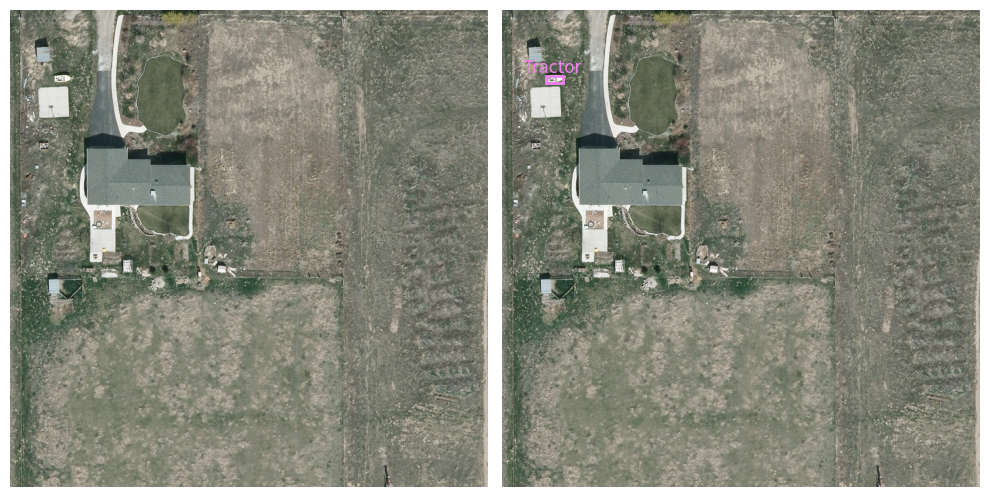

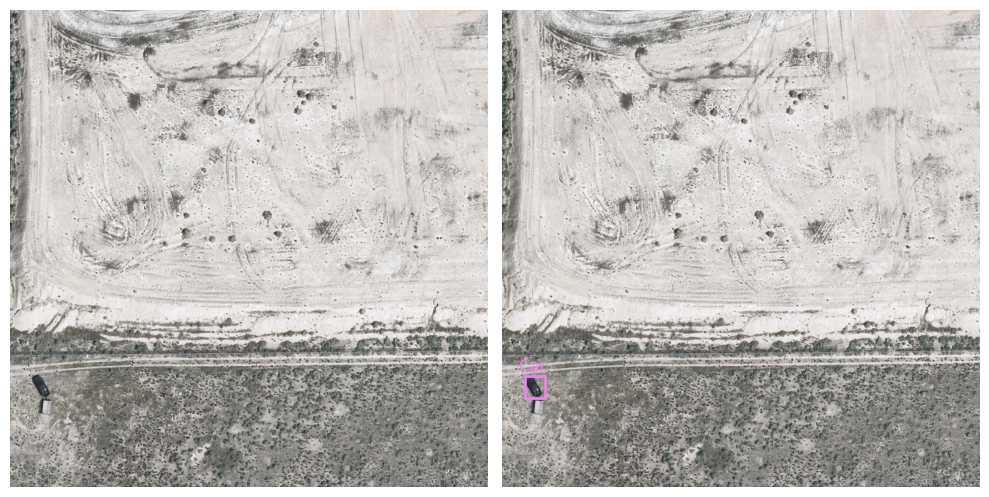

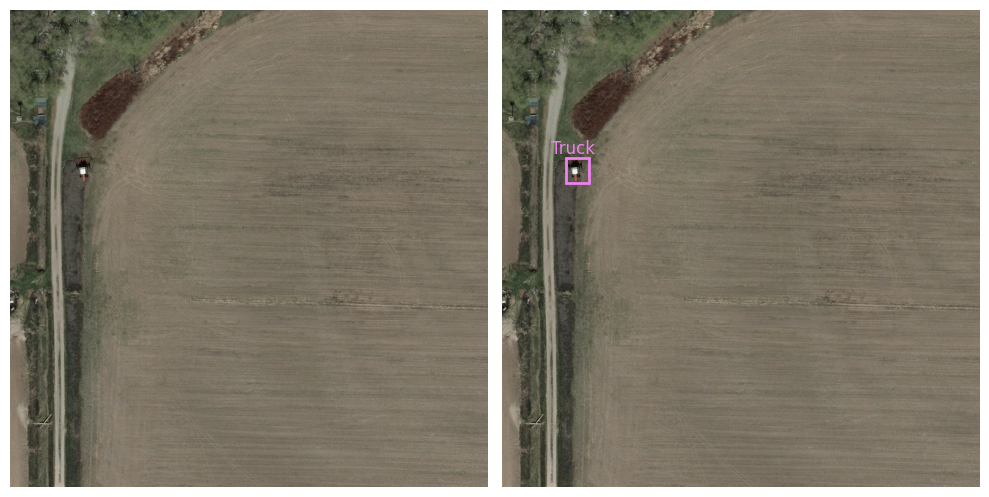

In [ ]:
dataset_config = {
    "data_dir": "./data/vedai/1024x1024/Vehicules1024",
    "annotation_dir": "./data/vedai/1024x1024/Annotations1024",
}
dataset = VEDAIDataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")
dataset.show_image(3);
dataset.show_image(1);
dataset.show_image(2);

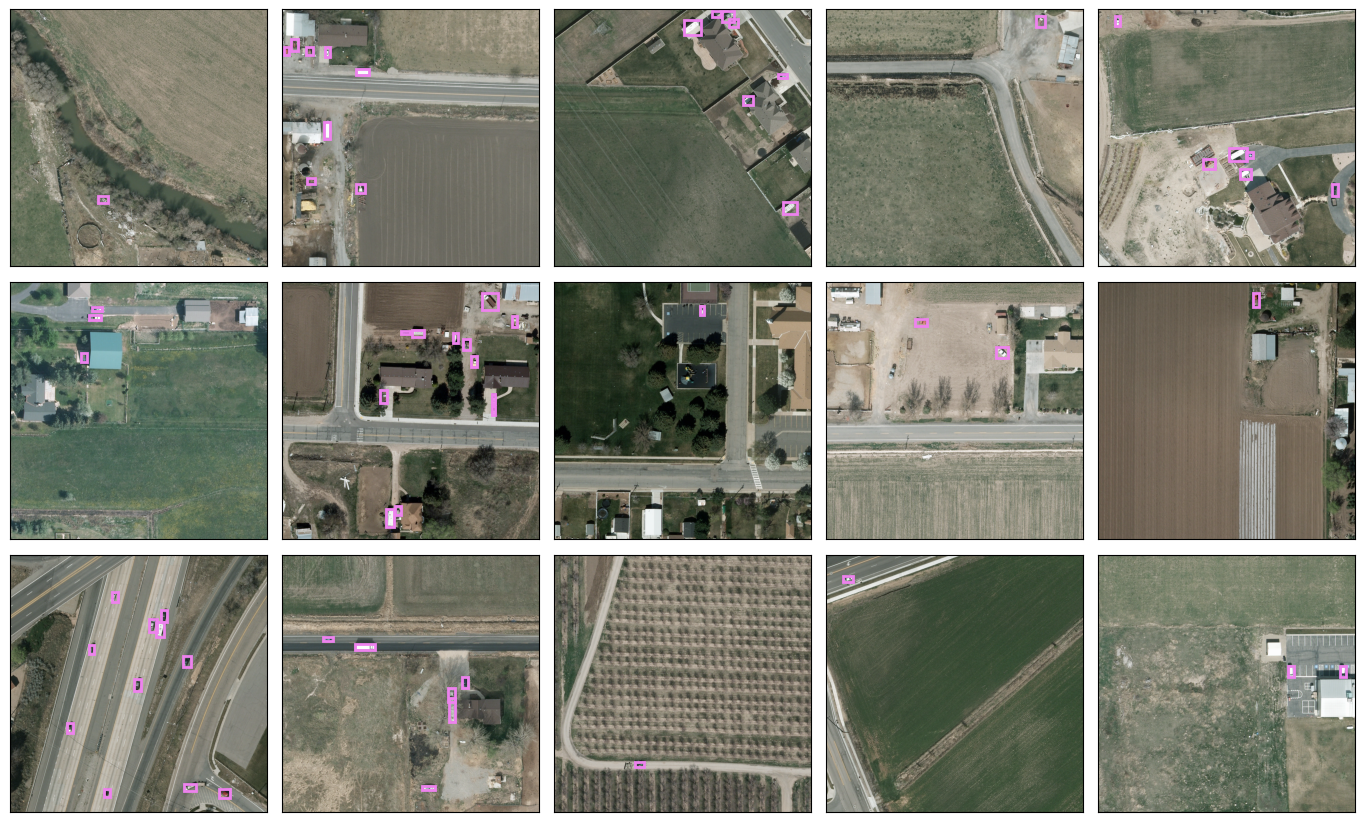

In [13]:
dataset.show_batch(15);

In [14]:
dataset.data_distribution_table()

,Label,Count
0,Small Land Vehicles,1408
1,Large Land Vehicles,307
2,Truck,190
3,Pickup,397
4,Vans,4
5,Plane,3
6,Others,101
7,Camping Car,204
8,Car,955
9,Tractor,171


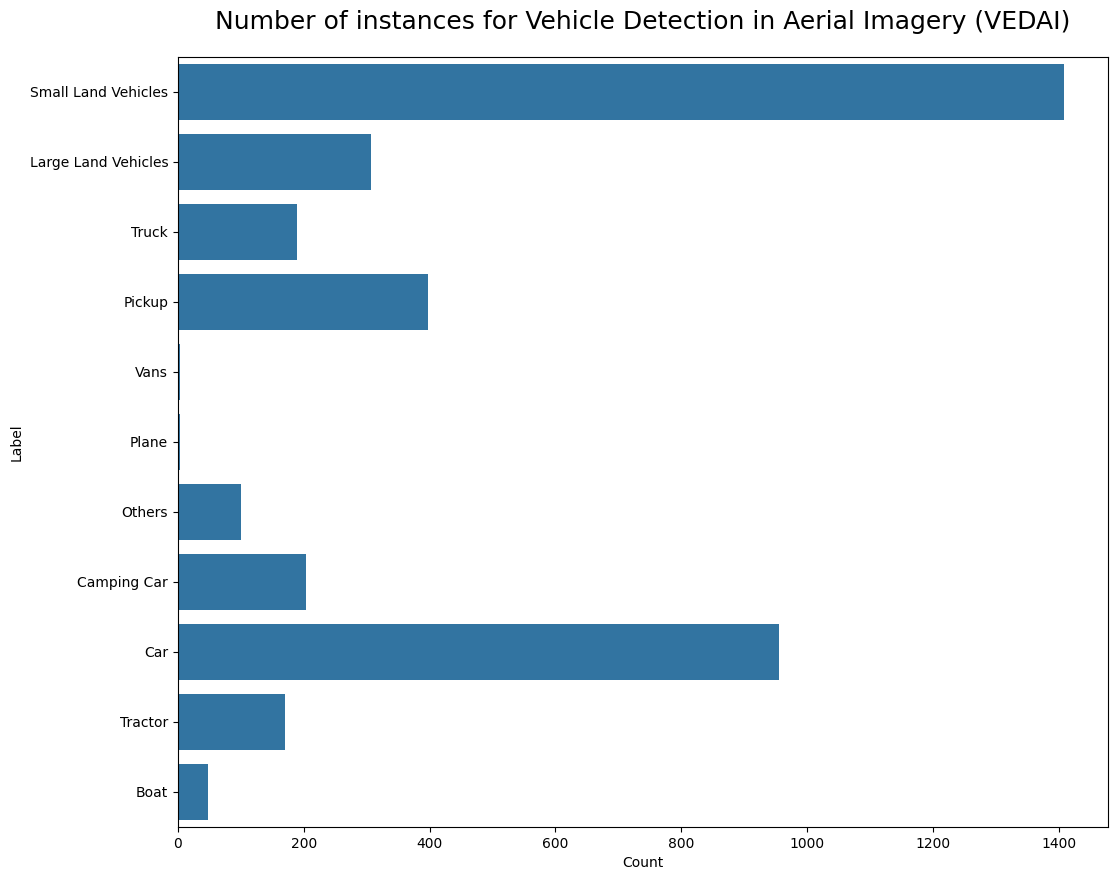

In [15]:
dataset.data_distribution_barchart();

## Load train data

In [ ]:
train_dataset_config = {
    "batch_size": 16,
    "shuffle": True,
    "num_workers": 4,
    "data_dir": "./data/vedai/1024x1024/Vehicules1024",
    "annotation_dir": "./data/vedai/1024x1024/Annotations1024",
    "csv_file" : "./data/vedai/1024x1024/train_co.csv",
    "joint_transforms": ["aitlas.transforms.ResizeToTensorV2"]
}
train_dataset = VEDAIDataset(train_dataset_config)

print(f"Total number of train images: {len(train_dataset)}")

Total number of train images: 1004


## Create the model

In [ ]:
epochs = 10
model_directory = "./data/experiments/vedai/"
model_config = {
    "num_classes": 12,
    "learning_rate": 0.0001,
    "pretrained": True,
    "metrics": ["map"]
}

model = FasterRCNN(model_config)
model.prepare()

## Start the training

In [26]:
model.train_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    run_id='1'
)

2025-09-19 08:36:30,845 INFO Starting training.
training: 100%|██████████| 63/63 [00:40<00:00,  1.55it/s]
2025-09-19 08:37:11,592 INFO epoch: 1, time: 41, loss:  0.46448
testing on train set: 100%|██████████| 63/63 [00:22<00:00,  2.85it/s]
2025-09-19 08:37:36,806 INFO map:0.08797530084848404, map_50:0.14647962152957916, map_75:0.09872058033943176, map_small:0.08935713022947311, map_medium:0.061766065657138824, map_large:-1.0, mar_1:0.07903466373682022, mar_10:0.13028058409690857, mar_100:0.13044120371341705, mar_small:0.1299142688512802, mar_medium:0.12793615460395813, mar_large:-1.0, map_per_class:tensor(0.4934), tensor(0.0079), tensor(0.0043), tensor(0.3912), tensor(0.), tensor(0.), tensor(0.), tensor(0.0043), tensor(0.0665), tensor(0.), tensor(0.), mar_100_per_class:tensor(0.6405), tensor(0.0161), tensor(0.0047), tensor(0.6536), tensor(0.), tensor(0.), tensor(0.), tensor(0.0171), tensor(0.1029), tensor(0.), tensor(0.), classes:tensor(1, dtype=torch.int32), tensor(2, dtype=torch.int3

0.07367371534743157

## Evaluate the model

In [ ]:
test_dataset_config = {
    "batch_size": 8,
    "shuffle": False,
    "data_dir": "./data/vedai/1024x1024/Vehicules1024",
    "annotation_dir": "./data/vedai/1024x1024/Annotations1024",
    "csv_file" : "./data/vedai/1024x1024/val_co.csv",
    "joint_transforms": ["aitlas.transforms.ResizeToTensorV2"]
}

test_dataset = VEDAIDataset(test_dataset_config)
print(f"Total number of test images: {len(test_dataset)}")

model = FasterRCNN(model_config)
model.prepare()
model.running_metrics.reset()
model_path = "./data/experiments/vedai/checkpoint.pth.tar"
model.evaluate(dataset=test_dataset, model_path=model_path)
model.running_metrics.get_scores(model.metrics)

Total number of test images: 121


2025-09-19 08:47:54,312 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/vedai/checkpoint.pth.tar
2025-09-19 08:47:54,618 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/vedai/checkpoint.pth.tar at epoch 11
testing on test set: 100%|██████████| 16/16 [00:03<00:00,  4.68it/s]


[{'map': 0.36535680294036865,
  'map_50': 0.5976438522338867,
  'map_75': 0.40547218918800354,
  'map_small': 0.4123775064945221,
  'map_medium': 0.37508252263069153,
  'map_large': 0.0,
  'mar_1': 0.3171360194683075,
  'mar_10': 0.42222869396209717,
  'mar_100': 0.42222869396209717,
  'mar_small': 0.4760144352912903,
  'mar_medium': 0.43888887763023376,
  'mar_large': 0.0,
  'map_per_class': [tensor(0.4845),
   tensor(0.3795),
   tensor(0.3752),
   tensor(0.4681),
   tensor(0.6071),
   tensor(0.2723),
   tensor(0.3810),
   tensor(0.3205),
   tensor(0.)],
  'mar_100_per_class': [tensor(0.5872),
   tensor(0.4656),
   tensor(0.4381),
   tensor(0.5289),
   tensor(0.6167),
   tensor(0.3480),
   tensor(0.4489),
   tensor(0.3667),
   tensor(0.)],
  'classes': [tensor(1, dtype=torch.int32),
   tensor(2, dtype=torch.int32),
   tensor(3, dtype=torch.int32),
   tensor(4, dtype=torch.int32),
   tensor(7, dtype=torch.int32),
   tensor(8, dtype=torch.int32),
   tensor(9, dtype=torch.int32),
   tens

## Predictions

2025-09-19 08:48:01,642 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/vedai/checkpoint.pth.tar
2025-09-19 08:48:01,928 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/vedai/checkpoint.pth.tar at epoch 11


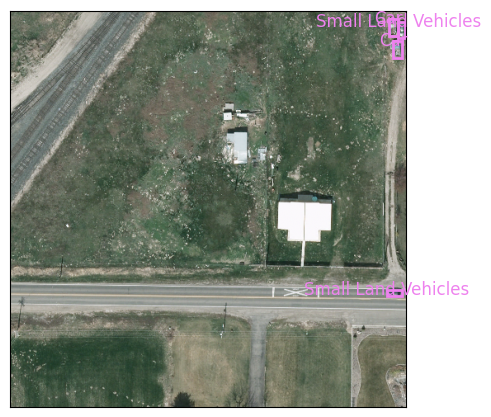

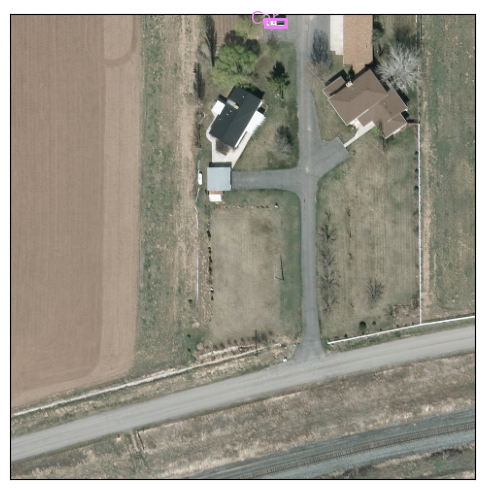

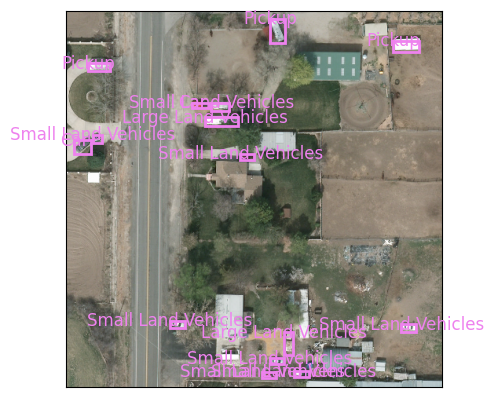

In [ ]:
model_config = {
    "num_classes": 12,
    "learning_rate": 0.0001,
    "pretrained": True,
    "metrics": ["map"]
}
model = FasterRCNN(model_config)
model.prepare()

model_path = "./data/experiments/vedai/checkpoint.pth.tar"
labels = ["no_data","Small Land Vehicles","Large Land Vehicles","Truck","Pickup","Vans","Plane","Others","Camping Car","Car","Tractor","Boat"]
transform = Resize()
model.load_model(model_path)

csv_file = "./data/vedai/1024x1024/test_co.csv"

test_list = []
with open(csv_file, mode ='r')as file:
    csvFile = csv.reader(file)
    for lines in csvFile:
        test_list.append(lines[0])

image = image_loader('./data/vedai/1024x1024/' + test_list[0])
fig = model.detect_objects(image, labels, transform)

image = image_loader('./data/vedai/1024x1024/' + test_list[5])
fig = model.detect_objects(image, labels, transform)

image = image_loader('./data/vedai/1024x1024/' + test_list[7])
fig = model.detect_objects(image, labels, transform)